# Example: Explicit Methods on Gene Circuits
A pulse of an inducer, a chemical added to the medium, can switch a gene circuit into a new state. We want to know whether the computed response changes when we change the solver or its time step.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Compare solutions on a shared time grid:__ Run explicit Euler and classical fourth-order Runge–Kutta through an inducer pulse. Compare the protein trajectories with a library reference.
> * __Measure the rate at which the error falls:__ Halve the step after the pulse, where the inducer concentration is constant. Compare the error and the number of rate evaluations for each method.
> * __Predict the Euler step limit:__ Compute the stability bound from the eigenvalues of the Jacobian at a steady state. Test the prediction on a circuit whose oscillations decay.

Tasks 1 and 2 use the memory circuit from Problem Set 6. Task 3 uses the negative feedback loop from the earlier gene circuit example.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package and the packages used here.

Let's set up our code environment:

In [1]:
# Load the local setup and choose the plot theme -
include(joinpath(@__DIR__, "Include.jl")); # load the shared course environment and the example's imports

# Choose one theme, then rerun the plotting cells after a change -
theme(:default); # light background
# theme(:dark); # dark background

[The `balances!(...)` function](../../../code/src/GeneNetworks.jl) of the course package computes the rates of change of a circuit. The state is the concentration vector: the messenger RNA (mRNA) concentrations, followed by the protein concentrations.

In the [memory circuit](config/memory.toml), the inducer activates protein X. Protein X activates genes Y and Z, whose proteins activate each other's genes. A pulse of the inducer can switch the circuit from a low state to a high state that stays after the pulse ends.

Let's choose the settings:

In [2]:
# the fixed-step runs of Task 1 -
Δt = 1.0; # the time step of Euler and RK4 (min)
final_time = 480.0; # the end of the runs (min); the runs stop at the whole step nearest to it

# the inducer pulse. The inducer I starts at its baseline, the value initial under [inputs.I] in the config file.
# At pulse_start, I changes to pulse_concentration. After pulse_length minutes, I returns to the baseline.
# Both edges of the pulse are rounded to whole steps of Δt -
pulse_concentration = 4.0; # the inducer concentration during the pulse (µM)
pulse_start = 40.0; # the time the pulse starts (min)
pulse_length = 72.0; # how long the pulse lasts (min)

# the Euler runs of Task 3: two steps, given as multiples of the Euler step limit, one below the limit and one above it -
stability_factors = [0.65, 1.35]; # the step of each run, as a multiple of the limit
stability_final_time = 6000.0; # the end of the Task 3 runs (min)

___
## Task 1: Solve Through an Inducer Pulse
In this task, we ask whether explicit Euler and classical fourth-order Runge–Kutta (RK4) follow the pulse response of the memory circuit at the step `Δt`. We compare both methods with [the `Tsit5` solver](https://docs.sciml.ai/OrdinaryDiffEq/stable/explicit/Tsit5/), which adjusts its step to control the error.

The circuit starts at its low steady state, with the inducer at its baseline. [The `steady_state(...)` function](../../../code/src/GeneNetworks.jl) finds that state with a search that starts at zero mRNA and protein. Let's build the memory circuit and find its low steady state:

In [3]:
(model, x₀, protein_y) = let

    # initialize -
    path = joinpath(@__DIR__, "config", "memory.toml"); # the config file of the memory circuit
    t_start = 0.0; # the time at which the runs start (min)

    # build the model from the config file -
    model = build(MyGeneNetworkModel, path); # read the file, and build the model of the circuit
    N = length(model.genes); # the number of genes; the state is [m₁, ..., m_N, p₁, ..., p_N]
    protein_y = N + model.index["Y"]; # the entry of protein Y in the state: the N mRNA entries come first

    # the low steady state, with the inducer at its baseline -
    guess = zeros(2 * N); # start the search at zero mRNA and protein (nmol/gDW)
    solution = steady_state(model; guess = guess, t = t_start); # the state at which every balance is zero
    if solution.converged == false # the search did not reach a steady state
        error("No steady state was found. Undo the last change to the config file, and rerun the notebook."); # stop here
    end

    (model, solution.x, protein_y); # return
end;

[The `set_input!(...)` function](../../../code/src/GeneNetworks.jl) sets the inducer schedule of the model. The pulse edges are rounded to whole steps of `Δt`, which puts both edges on the fixed-step grid. Let's add the pulse to the model:

In [4]:
(pulse_on, pulse_end, t_final) = let

    # initialize -
    baseline = model.inputs["I"].initial; # the baseline inducer concentration from the config file (µM)
    pulse_on = round(pulse_start / Δt) * Δt; # the time the pulse starts, rounded to a whole step (min)
    pulse_end = round((pulse_start + pulse_length) / Δt) * Δt; # the time the pulse ends, rounded to a whole step (min)
    t_final = round(final_time / Δt) * Δt; # the end of the runs: the whole step nearest to final_time (min)

    # stop when the rounded pulse does not fit inside the runs -
    if (0.0 < pulse_on < pulse_end < t_final) == false # the pulse must start after zero, last at least one step, and end before the runs end
        error("The pulse does not fit inside the runs. Change pulse_start, pulse_length, or final_time, and rerun the notebook."); # stop here
    end

    # the pulse: I is pulse_concentration from pulse_on, and the baseline again from pulse_end -
    set_input!(model, "I", [pulse_on, pulse_end], [pulse_concentration, baseline]); # the two times at which I changes, and its value after each

    (pulse_on, pulse_end, t_final); # return
end;

[The `integrate(...)` function](../../../code/src/FixedStepMethods.jl) takes equal steps of size `Δt` with the method we choose.

For the reference, we call [the `solve(...)` function of the OrdinaryDiffEq package](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/) by its full name, because the course package also has a function with that name. The [`tstops` option](https://docs.sciml.ai/DiffEqDocs/stable/basics/common_solver_opts/#Output-Control) makes Tsit5 end a step at each pulse edge, where the inducer concentration jumps. Let's run Euler, RK4, and Tsit5 through the pulse:

In [5]:
(euler, rk4, reference) = let

    # initialize -
    t_start = 0.0; # the time at which the runs start (min)
    relative_tolerance = 1e-12; # the error Tsit5 allows, relative to each concentration
    absolute_tolerance = 1e-12; # the error Tsit5 allows near a concentration of zero (nmol/gDW)

    # Euler and RK4, with the same step Δt -
    euler = integrate(balances!, x₀, model; t_start = t_start, t_final = t_final, # the balances, the starting state, and the time span
        Δt = float(Δt), algorithm = ExplicitEulerMethod()); # explicit Euler: one rate evaluation per step; integrate needs a decimal step
    rk4 = integrate(balances!, x₀, model; t_start = t_start, t_final = t_final, # the same balances, starting state, and time span
        Δt = float(Δt), algorithm = RungeKutta4Method()); # RK4: four rate evaluations per step

    # the Tsit5 reference, which ends a step at each pulse edge -
    problem = ODEProblem(balances!, x₀, (t_start, t_final), model); # the balances, the starting state, the time span, and the model
    reference = OrdinaryDiffEq.solve(problem, Tsit5(); reltol = relative_tolerance, abstol = absolute_tolerance, # the tolerances of each step
        tstops = [pulse_on, pulse_end]); # the times at which a step must end

    (euler, rk4, reference); # return
end;

Each fixed-step run holds the times `t`, the states `x` with one row per time, and the count `evaluations`. The Tsit5 solution holds its times in `reference.t` and its states in `reference.u`. Let's plot the inducer in the top panel, and each protein in the bottom panel, with Tsit5 as a wide pale line, Euler dashed, and RK4 dotted:

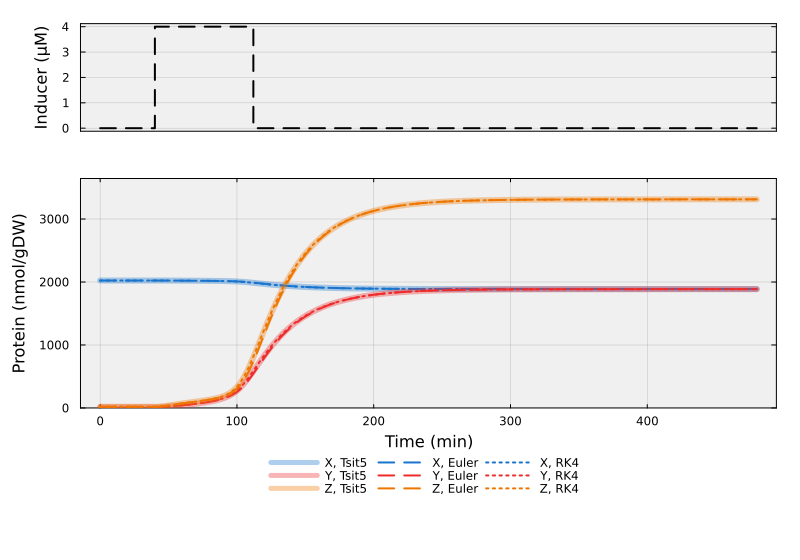

In [6]:
let

    # initialize -
    N = length(model.genes); # the number of genes; protein j is entry N + j of the state
    baseline = model.inputs["I"].initial; # the baseline inducer concentration (µM)
    colors = [:dodgerblue3, :firebrick2, :darkorange2]; # the color of the protein of gene 1, gene 2, and gene 3
    panel = RGBA(0.5, 0.5, 0.5, 0.12); # a see-through panel, for the light and the dark theme
    headroom = 1.1; # the top of the protein axis, as a multiple of the largest reference concentration
    largest = 0.0; # the largest reference concentration of any protein (nmol/gDW)

    # top panel: the inducer, as a dashed step line in the color of the legend text -
    top = plot(framestyle = :box, background_color_inside = panel, legend = false, xticks = false); # an empty panel for the inducer
    inducer_color = top[1][:legend_font_color]; # black on the light theme, white on the dark theme
    plot!(top, [0.0, pulse_on, pulse_end, t_final], [baseline, pulse_concentration, baseline, baseline], # the inducer before, during, and after the pulse
        seriestype = :steppost, lw = 2, ls = :dash, c = inducer_color); # each value holds until the next time
    ylabel!(top, "Inducer (µM)"); # the inducer axis

    # bottom panel: each protein from Tsit5, Euler, and RK4, in the color of its gene -
    bottom = plot(framestyle = :box, background_color_inside = panel, fg_legend = :transparent,
        legend = :outerbottom, legend_column = 3); # an empty panel for the proteins, with the legend below it
    for j ∈ 1:N # each gene
        name = model.genes[j].name; # the name of gene j
        color = :gray; # the color of a fourth or later gene
        if j <= length(colors) # one of the first three genes
            color = colors[j]; # its own color
        end
        p_reference = zeros(length(reference.t)); # protein j along the reference (nmol/gDW)
        for k ∈ 1:length(reference.t) # each Tsit5 time
            p_reference[k] = reference.u[k][N + j]; # the protein entries follow the N mRNA entries
        end
        largest = max(largest, maximum(p_reference)); # the largest reference concentration so far
        plot!(bottom, reference.t, p_reference, lw = 6, linealpha = 0.35, c = color, label = name * ", Tsit5"); # the reference, as a wide pale line
        plot!(bottom, euler.t, euler.x[:, N + j], lw = 2, ls = :dash, c = color, label = name * ", Euler"); # explicit Euler
        plot!(bottom, rk4.t, rk4.x[:, N + j], lw = 2, ls = :dot, c = color, label = name * ", RK4"); # RK4
    end
    ylims!(bottom, (0.0, headroom * largest)); # the range of the reference, so that a run that blows up leaves the panel
    xlabel!(bottom, "Time (min)"); # the time axis
    ylabel!(bottom, "Protein (nmol/gDW)"); # the protein axis

    # stack the two panels, with a shared time axis -
    plot(top, bottom, layout = grid(2, 1, heights = [0.25, 0.75]), link = :x, size = (800, 560), margin = 4 * Plots.mm); # the figure
end

Compare the Euler and RK4 traces of each protein with the reference at both edges of the inducer pulse. In the memory circuit, proteins Y and Z can keep rising after the inducer returns to its baseline, and then stay high.

Gene Z and its protein are shorter than gene Y and its protein in the config file. The shorter gene has a larger maximum transcription rate, and the shorter protein has a larger maximum translation rate. Protein Z settles above protein Y.

Protein X falls as proteins Y and Z rise. The Y and Z messenger RNAs compete with the X messenger RNA for ribosomes, the complexes that translate mRNA into protein.

___
## Task 2: Measure Error and Work
In this task, we ask how much the error of each method falls when we halve the step. A method of order $p$ has a global error proportional to $\Delta t^{p}$. For small steps, halving the step divides that error by about $2^{p}$, which is two for Euler and sixteen for RK4.

The order holds only where the rates change smoothly. The inducer concentration jumps at both pulse edges. We measure the error in a window after the pulse, where the inducer concentration stays at its baseline.

Every run starts from the Tsit5 state at the end of the pulse. We also count the rate evaluations of each run, which double with each halving. Let's compute the Tsit5 reference on the window:

In [7]:
(window_start, window_end, x_window, window_reference) = let

    # initialize -
    window_length = 48.0; # the length of the window after the pulse (min)
    relative_tolerance = 1e-12; # the error Tsit5 allows, relative to each concentration
    absolute_tolerance = 1e-12; # the error Tsit5 allows near a concentration of zero (nmol/gDW)
    window_start = pulse_end; # the window starts at the end of the pulse (min)
    window_end = pulse_end + window_length; # the end of the window (min)
    x_window = reference(window_start); # the Tsit5 state at the end of the pulse (nmol/gDW)

    # the Tsit5 reference on the window -
    problem = ODEProblem(balances!, x_window, (window_start, window_end), model); # the same balances, from the state at the end of the pulse
    window_reference = OrdinaryDiffEq.solve(problem, Tsit5(); reltol = relative_tolerance, abstol = absolute_tolerance); # the reference for this task

    (window_start, window_end, x_window, window_reference); # return
end;

At each time of a grid, the error of a run is the absolute difference between its concentration of protein Y and the reference concentration.

A Tsit5 solution such as `window_reference` can be [called at any time](https://docs.sciml.ai/DiffEqDocs/stable/basics/solution/) to interpolate the state. The keyword `idxs = protein_y` keeps only protein Y. Let's run Euler and RK4 on a sequence of grids, each with half the step of the one before, and compute the error at each time:

In [8]:
(step_sizes, window_runs, error_curves) = let

    # initialize -
    step_counts = [32, 64, 128]; # the number of steps on each grid; each count is twice the one before
    methods = [ExplicitEulerMethod(), RungeKutta4Method()]; # Euler in column 1, RK4 in column 2
    step_sizes = (window_end - window_start) ./ step_counts; # the step of each grid (min)
    window_runs = Array{NamedTuple}(undef, length(step_counts), length(methods)); # the run of each grid (row) and method (column), filled below
    error_curves = Array{Vector{Float64}}(undef, length(step_counts), length(methods)); # the error at each time of each run (nmol/gDW), filled below

    # run each method on each grid, and compare protein Y with the reference -
    for j ∈ 1:length(methods) # each method
        for i ∈ 1:length(step_counts) # each grid
            result = integrate(balances!, x_window, model; t_start = window_start, t_final = window_end, # the window after the pulse
                Δt = step_sizes[i], algorithm = methods[j]); # the step of grid i, with method j
            p_reference = window_reference(result.t; idxs = protein_y).u; # the reference protein Y at the times of the grid (nmol/gDW)
            window_runs[i, j] = result; # store the run
            error_curves[i, j] = abs.(result.x[:, protein_y] - p_reference); # the error at each time of the grid (nmol/gDW)
        end
    end

    (step_sizes, window_runs, error_curves); # return
end;

Let's plot the error of each run against time, with Euler in the left panel and RK4 in the right panel:

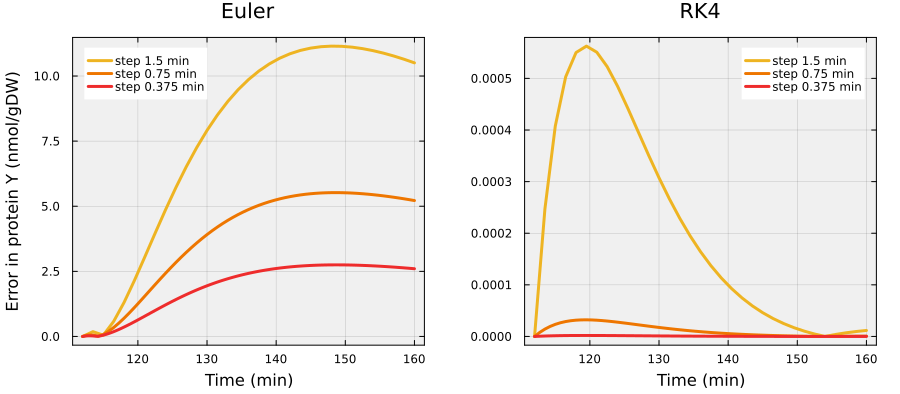

In [9]:
let

    # initialize -
    colors = [:goldenrod2, :darkorange2, :firebrick2]; # the color of each grid, from the coarsest to the finest
    panel = RGBA(0.5, 0.5, 0.5, 0.12); # a see-through panel, for the light and the dark theme

    # one panel for each method -
    left = plot(framestyle = :box, background_color_inside = panel, fg_legend = :transparent, legend = :topleft,
        title = "Euler"); # the Euler errors
    right = plot(framestyle = :box, background_color_inside = panel, fg_legend = :transparent, legend = :topright,
        title = "RK4"); # the RK4 errors

    # one error curve for each grid, in both panels -
    for i ∈ 1:length(step_sizes) # each grid
        color = :gray; # the color of a fourth or later grid
        if i <= length(colors) # one of the first three grids
            color = colors[i]; # its own color
        end
        label = "step $(round(step_sizes[i]; sigdigits = 3)) min"; # the legend entry of grid i
        plot!(left, window_runs[i, 1].t, error_curves[i, 1], lw = 3, c = color, label = label); # the Euler error on grid i
        plot!(right, window_runs[i, 2].t, error_curves[i, 2], lw = 3, c = color, label = label); # the RK4 error on grid i
    end
    xlabel!(left, "Time (min)"); # the time axis of the Euler panel
    xlabel!(right, "Time (min)"); # the time axis of the RK4 panel
    ylabel!(left, "Error in protein Y (nmol/gDW)"); # the error axis

    # the two panels side by side, each with its own error axis -
    plot(left, right, layout = (1, 2), size = (900, 395), margin = 4 * Plots.mm); # the figure
end

Each panel has its own error axis. Let's list the largest error of each run, the factor by which the error falls from the grid before, and the rate evaluations:

In [10]:
let

    # initialize -
    names = ["Euler", "RK4"]; # the methods, in the order of the columns of window_runs
    number_of_grids = length(step_sizes); # the number of grids
    largest_errors = zeros(number_of_grids, length(names)); # the largest error of each grid (row) and method (column) (nmol/gDW)
    method_column = String[]; # column 1: the method
    step_column = String[]; # column 2: the step (min)
    work_column = String[]; # column 3: the number of rate evaluations
    error_column = String[]; # column 4: the largest error (nmol/gDW)
    factor_column = String[]; # column 5: the largest error on the grid before, divided by the largest error on this grid

    # one row for each method and grid -
    for j ∈ 1:length(names) # each method
        for i ∈ 1:number_of_grids # each grid
            largest_errors[i, j] = maximum(error_curves[i, j]); # the largest error of this run (nmol/gDW)
            factor = "-"; # the coarsest grid has no grid before it
            if i > 1 # a finer grid
                factor = string(round(largest_errors[i - 1, j] / largest_errors[i, j]; sigdigits = 3)); # how many times smaller the error is than on the grid before
            end
            push!(method_column, names[j]); # the method
            push!(step_column, string(round(step_sizes[i]; sigdigits = 3))); # the step (min)
            push!(work_column, string(window_runs[i, j].evaluations)); # the rate evaluations
            push!(error_column, string(round(largest_errors[i, j]; sigdigits = 3))); # the largest error (nmol/gDW)
            push!(factor_column, factor); # the factor
        end
    end

    # show the table -
    pretty_table(hcat(method_column, step_column, work_column, error_column, factor_column); # the table
        backend = :text, # draw the table with text characters
        column_labels = ["method", "step (min)", "rate evaluations", "largest error (nmol/gDW)", "factor"], # the header of each column
        fit_table_in_display_horizontally = false, # show every column, even when the table is wider than the display
        alignment = :l); # left-align every column
end

┌────────┬────────────┬──────────────────┬──────────────────────────┬────────┐
│ method │ step (min) │ rate evaluations │ largest error (nmol/gDW) │ factor │
├────────┼────────────┼──────────────────┼──────────────────────────┼────────┤
│ Euler  │ 1.5        │ 32               │ 11.1                     │ -      │
│ Euler  │ 0.75       │ 64               │ 5.52                     │ 2.02   │
│ Euler  │ 0.375      │ 128              │ 2.75                     │ 2.01   │
│ RK4    │ 1.5        │ 128              │ 0.000562                 │ -      │
│ RK4    │ 0.75       │ 256              │ 3.22e-5                  │ 17.5   │
│ RK4    │ 0.375      │ 512              │ 1.93e-6                  │ 16.7   │
└────────┴────────────┴──────────────────┴──────────────────────────┴────────┘


The Euler factor is close to two, the factor that order one predicts. As the step shrinks, the RK4 factor approaches sixteen, the factor that order four predicts.

RK4 takes four rate evaluations per step. At an equal number of rate evaluations, the RK4 error is far below the Euler error.

___
## Task 3: Find and Test the Euler Step Limit
In this task, we ask at what step Euler stops preserving the decay of a circuit to its steady state. We use the [negative feedback loop](config/negative-feedback-loop.toml), in which protein X activates gene Y and protein Y represses gene X. The inducer stays at its baseline throughout this task.

Let's build the negative feedback loop and find its steady state:

In [11]:
(feedback, x_steady) = let

    # initialize -
    path = joinpath(@__DIR__, "config", "negative-feedback-loop.toml"); # the config file of the negative feedback loop
    t_start = 0.0; # the time (min); this model has no pulse, so the inducer stays at its baseline

    # build the model, and find its steady state -
    feedback = build(MyGeneNetworkModel, path); # read the file, and build the model of the circuit
    guess = zeros(2 * length(feedback.genes)); # start the search at zero mRNA and protein (nmol/gDW)
    solution = steady_state(feedback; guess = guess, t = t_start); # the state at which every balance is zero
    if solution.converged == false # the search did not reach a steady state
        error("No steady state was found. Undo the last change to the config file, and rerun the notebook."); # stop here
    end

    (feedback, solution.x); # return
end;

[The `jacobian(...)` function](../../../code/src/GeneNetworks.jl) computes the Jacobian at the steady state, the matrix of derivatives of the balances with respect to the state. Each eigenvalue $\lambda$ of the Jacobian gives a mode of the motion near the steady state. Under Euler, a decaying mode keeps decaying when $\Delta t < -2\operatorname{Re}(\lambda)/|\lambda|^{2}$.

The smallest of these limits is the step limit of the circuit, `Δt_limit`. Let's compute the eigenvalues and the limit of each mode:

In [12]:
Δt_limit = let

    # initialize -
    t_start = 0.0; # the time at which the Jacobian is evaluated (min)
    A = jacobian(feedback, x_steady, t_start); # the Jacobian at the steady state (1/min)
    λ = eigvals(A); # the eigenvalues of the Jacobian (1/min)
    limits = zeros(length(λ)); # the Euler step limit of each mode (min)

    # stop when a mode does not decay: Euler then has no step limit -
    if maximum(real.(λ)) >= 0.0 # a mode that does not decay
        error("The steady state has a mode that does not decay. Undo the last change to the config file, and rerun the notebook."); # stop here
    end

    # the step limit of each mode -
    for k ∈ 1:length(λ) # each eigenvalue
        limits[k] = -2.0 * real(λ[k]) / abs2(λ[k]); # Euler keeps mode k decaying for steps below this limit; abs2 gives |λ|² (min)
    end

    # show the table, with one row for each eigenvalue -
    table = hcat(round.(real.(λ); sigdigits = 4), round.(imag.(λ); sigdigits = 4), round.(limits; sigdigits = 4)); # the real part, the imaginary part, and the limit
    pretty_table(table; # the table
        backend = :text, # draw the table with text characters
        column_labels = ["Re λ (1/min)", "Im λ (1/min)", "Euler step limit (min)"], # the header of each column
        fit_table_in_display_horizontally = false); # show every column, even when the table is wider than the display

    minimum(limits); # return the step limit of the circuit: the smallest limit of any mode
end;

┌──────────────┬──────────────┬────────────────────────┐
│ Re λ (1/min) │ Im λ (1/min) │ Euler step limit (min) │
├──────────────┼──────────────┼────────────────────────┤
│      -0.1783 │     -0.06429 │                  9.926 │
│      -0.1783 │      0.06429 │                  9.926 │
│    -0.003231 │     -0.06429 │                   1.56 │
│    -0.003231 │      0.06429 │                   1.56 │
└──────────────┴──────────────┴────────────────────────┘


When every eigenvalue is real and negative, the fastest-decaying mode sets the limit. In the negative feedback loop, the slowly decaying complex pair has the smallest limit.

Let's run Euler from zero mRNA and protein at the steps `stability_factors` times `Δt_limit`, and solve the same problem with Tsit5:

In [13]:
(stability_runs, stability_reference) = let

    # initialize -
    t_start = 0.0; # the time at which the runs start (min)
    x_start = zeros(2 * length(feedback.genes)); # zero mRNA and protein at the start (nmol/gDW)
    relative_tolerance = 1e-12; # the error Tsit5 allows, relative to each concentration
    absolute_tolerance = 1e-12; # the error Tsit5 allows near a concentration of zero (nmol/gDW)
    stability_runs = NamedTuple[]; # the Euler run of each factor, in the order of stability_factors

    # Euler at each multiple of the step limit -
    for factor ∈ stability_factors # each factor
        step = factor * Δt_limit; # the step of this run (min)
        t_final = round(stability_final_time / step) * step; # the end of this run: the whole step nearest to stability_final_time (min)
        result = integrate(balances!, x_start, feedback; t_start = t_start, t_final = t_final, # the balances, the starting state, and the time span
            Δt = step, algorithm = ExplicitEulerMethod()); # explicit Euler at this step
        push!(stability_runs, result); # store the run
    end

    # the Tsit5 reference over the same time span -
    problem = ODEProblem(balances!, x_start, (t_start, stability_final_time), feedback); # the same balances and starting state
    stability_reference = OrdinaryDiffEq.solve(problem, Tsit5(); reltol = relative_tolerance, abstol = absolute_tolerance); # the reference solution

    (stability_runs, stability_reference); # return
end;

Let's plot protein Y near the end of the runs, after the changes from the starting state have faded:

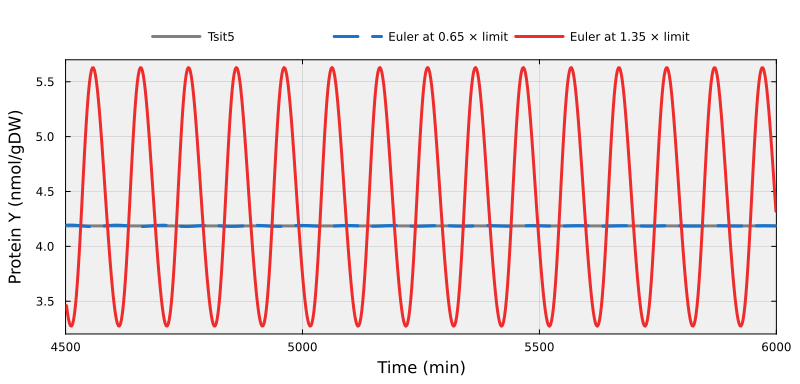

In [14]:
let

    # initialize -
    y = length(feedback.genes) + feedback.index["Y"]; # the entry of protein Y in the state: the mRNA entries come first
    tail_fraction = 0.75; # the figure starts after this fraction of the run time
    tail_start = tail_fraction * stability_final_time; # the first time in the figure (min)
    colors = [:dodgerblue3, :firebrick2]; # the color of each Euler run, in the order of stability_factors
    styles = [:dash, :solid]; # the line style of each Euler run
    panel = RGBA(0.5, 0.5, 0.5, 0.12); # a see-through panel, for the light and the dark theme

    # the reference: protein Y at each Tsit5 time in the figure -
    t_tail = Float64[]; # the Tsit5 times in the figure (min)
    p_tail = Float64[]; # protein Y at those times (nmol/gDW)
    for k ∈ 1:length(stability_reference.t) # each Tsit5 time
        if stability_reference.t[k] >= tail_start # a time in the figure
            push!(t_tail, stability_reference.t[k]); # store the time
            push!(p_tail, stability_reference.u[k][y]); # store protein Y at that time
        end
    end
    figure = plot(t_tail, p_tail, lw = 3, c = :gray, label = "Tsit5", # the reference
        framestyle = :box, background_color_inside = panel, fg_legend = :transparent, # the house style
        legend = :outertop, legend_column = 3, size = (800, 385), margin = 4 * Plots.mm); # the legend above the panel

    # each Euler run, from its first step in the figure -
    for j ∈ 1:length(stability_runs) # each run
        result = stability_runs[j]; # the run at factor j
        first_k = searchsortedfirst(result.t, tail_start); # the first step at or after tail_start
        plot!(figure, result.t[first_k:end], result.x[first_k:end, y], lw = 3, ls = styles[j], c = colors[j], # protein Y from this run
            label = "Euler at $(stability_factors[j]) × limit"); # the legend entry
    end
    xlims!(figure, (tail_start, stability_final_time)); # the end of the runs
    xlabel!(figure, "Time (min)"); # the time axis
    ylabel!(figure, "Protein Y (nmol/gDW)"); # the protein axis

    figure; # return
end

The eigenvalue bound predicts that the Euler run below the limit settles, and that the run above the limit keeps oscillating. The reference solves the same circuit. An oscillation that only Euler shows comes from the numerical step.

### Things to Try
* __Move the steps closer to the limit.__ Change both entries of `stability_factors` to values closer to one, and rerun Task 3. Does the run below the limit still settle?
* __Increase the time step.__ Raise `Δt` and rerun Task 1. At what step does the Euler trace leave the reference? Does RK4 still follow the reference at that step?
* __Shorten the pulse.__ Shorten `pulse_length` and rerun Task 1. Does protein Y stay high after the pulse?

___

## Summary
We compared two fixed-step methods with a library solver through an inducer pulse. We then measured their errors after the pulse, and used the eigenvalues at a steady state to predict the Euler step limit.

> __Key Takeaways:__
>
> * __Fixed-step methods can follow a pulse:__ We ran Euler and RK4 with the same step through an inducer pulse and compared the protein concentrations with a library reference. At a small enough step, both traces followed the reference through both edges of the pulse.
> * __The error and the work depend on the method:__ We halved the step after the pulse and measured how much the largest error fell. Runge–Kutta reduced the error faster, and reached a given error with fewer rate evaluations.
> * __A numerical step can sustain an oscillation:__ We found the Euler step limit from the eigenvalues of the negative feedback loop. A step above that limit sustained an oscillation while the library reference settled.

The eigenvalue calculation gives a bound to check before using Euler to interpret an oscillating circuit.

___